In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Đường dẫn dataset
DATA_DIR = Path("../data/raw/gsm8k")

TRAIN_PATH = DATA_DIR / "train-00000-of-00001.parquet"
TEST_PATH = DATA_DIR / "test-00000-of-00001.parquet"

# Đọc dữ liệu
train_df = pd.read_parquet(TRAIN_PATH)
test_df = pd.read_parquet(TEST_PATH)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (7473, 2)
Test shape: (1319, 2)


In [3]:
print("TRAIN COLUMNS:")
print(train_df.columns.tolist())

print("\nTRAIN INFO:")
train_df.info()

print("\nTEST COLUMNS:")
print(test_df.columns.tolist())

print("\nTRAIN SAMPLE:")
display(train_df.head())

TRAIN COLUMNS:
['question', 'answer']

TRAIN INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7473 entries, 0 to 7472
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  7473 non-null   object
 1   answer    7473 non-null   object
dtypes: object(2)
memory usage: 116.9+ KB

TEST COLUMNS:
['question', 'answer']

TRAIN SAMPLE:


,question,answer
0,Natalia sold clips to 48 of her friends in Apr...,Natalia sold 48/2 = <<48/2=24>>24 clips in May...
1,Weng earns $12 an hour for babysitting. Yester...,Weng earns 12/60 = $<<12/60=0.2>>0.2 per minut...
2,Betty is saving money for a new wallet which c...,"In the beginning, Betty has only 100 / 2 = $<<..."
3,"Julie is reading a 120-page book. Yesterday, s...",Maila read 12 x 2 = <<12*2=24>>24 pages today....
4,James writes a 3-page letter to 2 different fr...,He writes each friend 3*2=<<3*2=6>>6 pages a w...


In [4]:
print("TRAIN MISSING VALUES:")
print(train_df.isnull().sum())

print("\nTEST MISSING VALUES:")
print(test_df.isnull().sum())

print("\nTRAIN DUPLICATES:")
print(train_df.duplicated().sum())

print("\nTEST DUPLICATES:")
print(test_df.duplicated().sum())

TRAIN MISSING VALUES:
question    0
answer      0
dtype: int64

TEST MISSING VALUES:
question    0
answer      0
dtype: int64

TRAIN DUPLICATES:
0

TEST DUPLICATES:
0


In [5]:
for i in range(5):
    print(f"\n========== SAMPLE {i + 1} ==========")

    print("QUESTION:")
    print(train_df.iloc[i]["question"])

    print("\nANSWER:")
    print(train_df.iloc[i]["answer"])


========== SAMPLE 1 ==========
QUESTION:
Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?

ANSWER:
Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
#### 72

========== SAMPLE 2 ==========
QUESTION:
Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?

ANSWER:
Weng earns 12/60 = $<<12/60=0.2>>0.2 per minute.
Working 50 minutes, she earned 0.2 x 50 = $<<0.2*50=10>>10.
#### 10

========== SAMPLE 3 ==========
QUESTION:
Betty is saving money for a new wallet which costs $100. Betty has only half of the money she needs. Her parents decided to give her $15 for that purpose, and her grandparents twice as much as her parents. How much more money does Betty need to buy the wallet?

ANSWER:
In the beginning, Betty has only 100 / 2 = $<<100/2=50>>50.
Betty's gran

In [6]:
# Tạo các đặc trưng thống kê
train_df["question_length"] = train_df["question"].str.len()
train_df["answer_length"] = train_df["answer"].str.len()

print("Question length:")
print(train_df["question_length"].describe())

print("\nAnswer length:")
print(train_df["answer_length"].describe())

Question length:
count    7473.000000
mean      234.507427
std        93.904275
min        42.000000
25%       168.000000
50%       217.000000
75%       280.000000
max       985.000000
Name: question_length, dtype: float64

Answer length:
count    7473.000000
mean      287.495383
std       143.614403
min        50.000000
25%       182.000000
50%       257.000000
75%       361.000000
max      1228.000000
Name: answer_length, dtype: float64


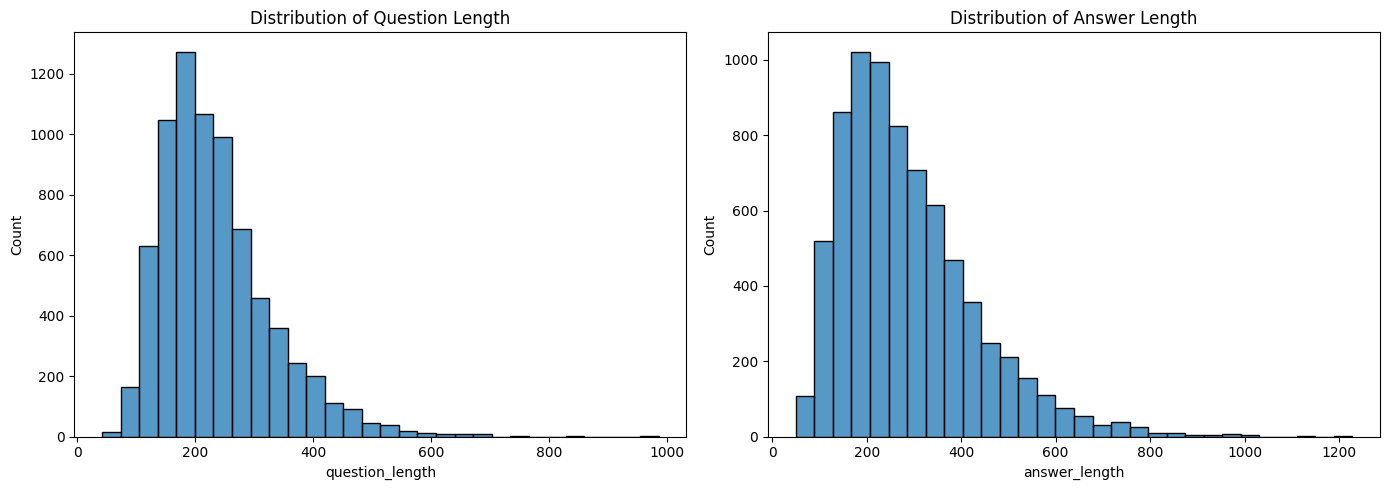

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    train_df["question_length"],
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Distribution of Question Length")

sns.histplot(
    train_df["answer_length"],
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Distribution of Answer Length")

plt.tight_layout()
plt.show()

In [8]:
print("Số mẫu có ký hiệu ####:")
print(train_df["answer"].str.contains("####", na=False).sum())

print("\nMột số đáp án cuối:")
for answer in train_df["answer"].head(5):
    if "####" in answer:
        print(answer.split("####")[-1].strip())

Số mẫu có ký hiệu ####:
7473

Một số đáp án cuối:
72
10
5
42
624


In [9]:
OUTPUT_DIR = Path("../results/tables")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Number of Samples": [
        len(train_df),
        len(test_df)
    ],
    "Number of Columns": [
        len(train_df.columns),
        len(test_df.columns)
    ],
    "Missing Values": [
        train_df[["question", "answer"]].isnull().sum().sum(),
        test_df[["question", "answer"]].isnull().sum().sum()
    ]
})

display(summary)

summary.to_csv(
    OUTPUT_DIR / "gsm8k_dataset_summary.csv",
    index=False
)

,Dataset,Number of Samples,Number of Columns,Missing Values
0,Train,7473,4,0
1,Test,1319,2,0


In [10]:
# Lấy mẫu thử nghiệm cố định
pilot_df = train_df.sample(
    n=50,
    random_state=42
).copy()

pilot_df = pilot_df.reset_index(drop=True)

# Lưu dữ liệu thử nghiệm
PILOT_DIR = Path("../data/processed")
PILOT_DIR.mkdir(parents=True, exist_ok=True)

pilot_df.to_parquet(
    PILOT_DIR / "gsm8k_pilot_50.parquet",
    index=False
)

print("Pilot dataset:", pilot_df.shape)

Pilot dataset: (50, 4)
